# House Price Prediction

## 1. Problem Statement
With 79 explanatory variables describing (almost) every aspect of residential homes in Ames, Iowa, this competition challenges you to predict the final price of each home.

## 2. Data Description

- SalePrice - the property's sale price in dollars. This is the target variable that you're trying to predict.
- MSSubClass: The building class
- MSZoning: The general zoning classification
- LotFrontage: Linear feet of street connected to property
- LotArea: Lot size in square feet
- Street: Type of road access
- Alley: Type of alley access
- LotShape: General shape of property
- LandContour: Flatness of the property
- Utilities: Type of utilities available
- LotConfig: Lot configuration
- LandSlope: Slope of property
- Neighborhood: Physical locations within Ames city limits
- Condition1: Proximity to main road or railroad
- Condition2: Proximity to main road or railroad (if a second is present)
- BldgType: Type of dwelling
- HouseStyle: Style of dwelling
- OverallQual: Overall material and finish quality
- OverallCond: Overall condition rating
- YearBuilt: Original construction date
- YearRemodAdd: Remodel date
- RoofStyle: Type of roof
- RoofMatl: Roof material
- Exterior1st: Exterior covering on house
- Exterior2nd: Exterior covering on house (if more than one material)
- MasVnrType: Masonry veneer type
- MasVnrArea: Masonry veneer area in square feet
- ExterQual: Exterior material quality
- ExterCond: Present condition of the material on the exterior
- Foundation: Type of foundation
- BsmtQual: Height of the basement
- BsmtCond: General condition of the basement
- BsmtExposure: Walkout or garden level basement walls
- BsmtFinType1: Quality of basement finished area
- BsmtFinSF1: Type 1 finished square feet
- BsmtFinType2: Quality of second finished area (if present)
- BsmtFinSF2: Type 2 finished square feet
- BsmtUnfSF: Unfinished square feet of basement area
- TotalBsmtSF: Total square feet of basement area
- Heating: Type of heating
- HeatingQC: Heating quality and condition
- CentralAir: Central air conditioning
- Electrical: Electrical system
- 1stFlrSF: First Floor square feet
- 2ndFlrSF: Second floor square feet
- LowQualFinSF: Low quality finished square feet (all floors)
- GrLivArea: Above grade (ground) living area square feet
- BsmtFullBath: Basement full bathrooms
- BsmtHalfBath: Basement half bathrooms
- FullBath: Full bathrooms above grade
- HalfBath: Half baths above grade
- Bedroom: Number of bedrooms above basement level
- Kitchen: Number of kitchens
- KitchenQual: Kitchen quality
- TotRmsAbvGrd: Total rooms above grade (does not include bathrooms)
- Functional: Home functionality rating
- Fireplaces: Number of fireplaces
- FireplaceQu: Fireplace quality
- GarageType: Garage location
- GarageYrBlt: Year garage was built
- GarageFinish: Interior finish of the garage
- GarageCars: Size of garage in car capacity
- GarageArea: Size of garage in square feet
- GarageQual: Garage quality
- GarageCond: Garage condition
- PavedDrive: Paved driveway
- WoodDeckSF: Wood deck area in square feet
- OpenPorchSF: Open porch area in square feet
- EnclosedPorch: Enclosed porch area in square feet
- 3SsnPorch: Three season porch area in square feet
- ScreenPorch: Screen porch area in square feet
- PoolArea: Pool area in square feet
- PoolQC: Pool quality
- Fence: Fence quality
- MiscFeature: Miscellaneous feature not covered in other categories
- MiscVal: $Value of miscellaneous feature
- MoSold: Month Sold
- YrSold: Year Sold
- SaleType: Type of sale
- SaleCondition: Condition of sale

## 3. Data EDA

### 3.1 Data Structure and Quality

#### 3.1.1 Shape and Types

In [1]:
import os

import numpy as np
import pandas as pd

# Kaggle path when running on Kaggle, otherwise train.csv / test.csv next to the notebook
KAGGLE_DIR = '/kaggle/input/competitions/house-prices-advanced-regression-techniques/'
DATA_DIR = KAGGLE_DIR if os.path.exists(KAGGLE_DIR) else './'
OUTPUT_DIR = '/kaggle/working/' if os.path.exists('/kaggle/working') else './'

# importing the dataset
house_pricing = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'))

In [2]:
house_pricing.head(5)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
# checking the shape of the data
house_pricing.shape

(1460, 81)

In [4]:
house_pricing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

##### 3.1.1.1 Separating features into Numeric, Categorical, Ordinal

In [5]:
numeric_features = house_pricing.select_dtypes(include=["int64", "float64"]).columns.tolist()
numeric_features

['Id',
 'MSSubClass',
 'LotFrontage',
 'LotArea',
 'OverallQual',
 'OverallCond',
 'YearBuilt',
 'YearRemodAdd',
 'MasVnrArea',
 'BsmtFinSF1',
 'BsmtFinSF2',
 'BsmtUnfSF',
 'TotalBsmtSF',
 '1stFlrSF',
 '2ndFlrSF',
 'LowQualFinSF',
 'GrLivArea',
 'BsmtFullBath',
 'BsmtHalfBath',
 'FullBath',
 'HalfBath',
 'BedroomAbvGr',
 'KitchenAbvGr',
 'TotRmsAbvGrd',
 'Fireplaces',
 'GarageYrBlt',
 'GarageCars',
 'GarageArea',
 'WoodDeckSF',
 'OpenPorchSF',
 'EnclosedPorch',
 '3SsnPorch',
 'ScreenPorch',
 'PoolArea',
 'MiscVal',
 'MoSold',
 'YrSold',
 'SalePrice']

In [6]:
# checking suspicious numeric columns
for col in numeric_features:
    if house_pricing[col].nunique() < 15:
        print(col, house_pricing[col].unique())

OverallQual [ 7  6  8  5  9  4 10  3  1  2]
OverallCond [5 8 6 7 4 2 3 9 1]
BsmtFullBath [1 0 2 3]
BsmtHalfBath [0 1 2]
FullBath [2 1 3 0]
HalfBath [1 0 2]
BedroomAbvGr [3 4 1 2 0 5 6 8]
KitchenAbvGr [1 2 3 0]
TotRmsAbvGrd [ 8  6  7  9  5 11  4 10 12  3  2 14]
Fireplaces [0 1 2 3]
GarageCars [2 3 1 0 4]
PoolArea [  0 512 648 576 555 480 519 738]
MoSold [ 2  5  9 12 10  8 11  4  1  7  3  6]
YrSold [2008 2007 2006 2009 2010]


`OverallQual`, `OverallCond` are ordinal features

There's also `MSSubClass` which consists of codes for the type of dwelling, the codes have no numerical/ordinal significance
Thus,

`MSSubClass` is categorical feature

In [7]:
# checking binary features
object_cols = house_pricing.select_dtypes(include=["object", "string"]).columns.tolist()

categorical_binary_features = []
doubtful_features = []

for col in object_cols:
    n_unique = house_pricing[col].nunique(dropna=True)

    if n_unique == 2:
        categorical_binary_features.append(col)
    else:
        doubtful_features.append(col)

categorical_binary_features

['Street', 'Alley', 'Utilities', 'CentralAir']

In [8]:
for col in categorical_binary_features:
    print(house_pricing[col].value_counts())
    print("----------")

Street
Pave    1454
Grvl       6
Name: count, dtype: int64
----------
Alley
Grvl    50
Pave    41
Name: count, dtype: int64
----------
Utilities
AllPub    1459
NoSeWa       1
Name: count, dtype: int64
----------
CentralAir
Y    1365
N      95
Name: count, dtype: int64
----------


In [9]:
house_pricing.groupby("Street")["SalePrice"].mean()

Street
Grvl    130190.500000
Pave    181130.538514
Name: SalePrice, dtype: float64

In [10]:
house_pricing.groupby("Utilities")["SalePrice"].mean()

Utilities
AllPub    180950.95682
NoSeWa    137500.00000
Name: SalePrice, dtype: float64

Even though `Street`, `Utilities` have a very high class bias, they seem to have some effect on the target, so they are not being dropped

In [11]:
doubtful_features

['MSZoning',
 'LotShape',
 'LandContour',
 'LotConfig',
 'LandSlope',
 'Neighborhood',
 'Condition1',
 'Condition2',
 'BldgType',
 'HouseStyle',
 'RoofStyle',
 'RoofMatl',
 'Exterior1st',
 'Exterior2nd',
 'MasVnrType',
 'ExterQual',
 'ExterCond',
 'Foundation',
 'BsmtQual',
 'BsmtCond',
 'BsmtExposure',
 'BsmtFinType1',
 'BsmtFinType2',
 'Heating',
 'HeatingQC',
 'Electrical',
 'KitchenQual',
 'Functional',
 'FireplaceQu',
 'GarageType',
 'GarageFinish',
 'GarageQual',
 'GarageCond',
 'PavedDrive',
 'PoolQC',
 'Fence',
 'MiscFeature',
 'SaleType',
 'SaleCondition']

Finally, after analysis
- `OverallQual`
- `OverallCond`
- `ExterQual`
- `ExterCond`
- `BsmtQual`
- `BsmtCond`
- `BsmtExposure`
- `BsmtFinType1`
- `BsmtFinType2`
- `HeatingQC`
- `KitchenQual`
- `FireplaceQu`
- `GarageQual`
- `GarageCond`
- `PoolQC`
- `LandSlope`
- `LotShape`
- `Functional`

are found to be ordinal

In [12]:
# setting up ordinal scales
quality_scale = {
    'None': 0,
    'Po': 1,
    'Fa': 2,
    'TA': 3,
    'Gd': 4,
    'Ex': 5
}

bsmt_finish_scale = {
    'None': 0,
    'Unf': 1,
    'LwQ': 2,
    'Rec': 3,
    'BLQ': 4,
    'ALQ': 5,
    'GLQ': 6
}

land_slope_scale = {
    'Sev': 1,
    'Mod': 2,
    'Gtl': 3
}

lot_shape_scale = {
    'IR3': 1,
    'IR2': 2,
    'IR1': 3,
    'Reg': 4
}

functional_scale = {
    'Sal': 1,
    'Sev': 2,
    'Maj2': 3,
    'Maj1': 4,
    'Mod': 5,
    'Min2': 6,
    'Min1': 7,
    'Typ': 8
}

bsmt_exp_scale = {
    'None': 0,
    'No': 1,
    'Mn': 2,
    'Av': 3,
    'Gd': 4
}

In [13]:
# ordinal mapping
ordinal_mappings = {
    'ExterQual': quality_scale,
    'ExterCond': quality_scale,
    'BsmtQual': quality_scale,
    'BsmtCond': quality_scale,
    'BsmtExposure': bsmt_exp_scale,
    'HeatingQC': quality_scale,
    'KitchenQual': quality_scale,
    'FireplaceQu': quality_scale,
    'GarageQual': quality_scale,
    'GarageCond': quality_scale,
    'PoolQC': quality_scale,
    'BsmtFinType1': bsmt_finish_scale,
    'BsmtFinType2': bsmt_finish_scale,
    'LandSlope': land_slope_scale,
    'LotShape': lot_shape_scale,
    'Functional': functional_scale,
    'OverallQual': None,
    'OverallCond': None,
}

In [14]:
ordinal_features = list(ordinal_mappings.keys())

categorical_features = [
    col for col in object_cols
    if col not in ordinal_features
]
categorical_features.append("MSSubClass")

numeric_features = [
    col for col in house_pricing.columns
    if col not in categorical_features
       and col not in ordinal_features
       and col != "SalePrice"
       and col != "Id"
]

In [15]:
# checking if some cols got left or were duplicated
print(len(numeric_features))
print(len(ordinal_features))
print(len(categorical_features))

33
18
28


Sum = 80, which checks out as the target was removed

In [16]:
FEATURE_TYPES = {
    "ordinal": ordinal_features,
    "nominal": categorical_features,
    "numeric": numeric_features
}

#### 3.1.2 Missing Values

In [17]:
# assessing the missing values
missing = pd.DataFrame({
    "Missing_Count": house_pricing.isna().sum(),
    "Missing_Percentage": house_pricing.isna().mean() * 100
})

missing = missing[missing["Missing_Count"] > 0]
missing.sort_values("Missing_Count", ascending=False)

,Missing_Count,Missing_Percentage
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


Apart from `LotFrontage`, `Electrical` all are structural absence

Structural absence is information, not a gap, so it is filled with an explicit value **before** any imputer runs:

- **Nominal** columns where NaN means "the house has none of this" get the category `"None"`. Without this, `SimpleImputer(most_frequent)` would give a house with no alley the most common alley type.
- **Numeric** areas and counts that are NaN because the thing is absent get `0` (no veneer, no basement).
- **Ordinal** columns are already handled: `OrdinalMapper` maps NaN to `"None"` → 0.
- `LotFrontage` and `Electrical` are genuinely missing and stay NaN for the pipeline's imputers.

These fills don't depend on the data (constants only), so doing them outside the CV pipeline causes no leakage. The same function is applied to the test set later.

In [20]:
STRUCTURAL_NOMINAL = ['Alley', 'Fence', 'MiscFeature', 'GarageType', 'GarageFinish', 'MasVnrType']
STRUCTURAL_ZERO = ['MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
                   'BsmtFullBath', 'BsmtHalfBath']


def fill_structural_missing(df):
    df = df.copy()
    df[STRUCTURAL_NOMINAL] = df[STRUCTURAL_NOMINAL].fillna('None')
    df[STRUCTURAL_ZERO] = df[STRUCTURAL_ZERO].fillna(0)
    return df


house_pricing = fill_structural_missing(house_pricing)
house_pricing[STRUCTURAL_NOMINAL + STRUCTURAL_ZERO].isna().sum().sum()

np.int64(0)

### 3.2 Univariate Analysis

#### 3.2.1 Analysing the target variable

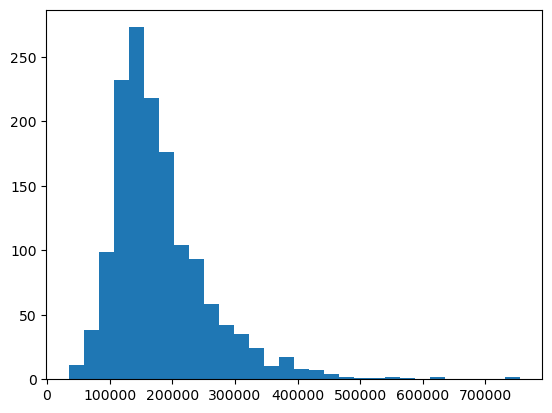

In [21]:
import matplotlib.pyplot as plt

plt.hist(house_pricing["SalePrice"], bins=30);

In [ ]:
house_pricing['SalePrice'].skew()

`SalePrice` is **right-skewed**: a long tail of expensive houses. A log transform should help even though we're using tree-based models, because it changes the loss the trees minimise (errors become relative instead of being dominated by expensive houses).

After we know the feature importance we can selectively check the skewness of the important features. If it's large (>2) we can transform them, for (potentially) better results.

#### 3.2.2 Analysing categorical features

In [22]:
with open('categorical_univariate_analysis.txt', 'w') as file:
    for features in FEATURE_TYPES["nominal"]:
        file.write(house_pricing.groupby(features)["SalePrice"].mean().sort_values().to_string())
        file.write("\n-------------------\n")

After analysing the text file, it's safe to say there's no low-signal categorical features, as the $max(mean) - min(mean)$ for every category is significant.

#### 3.2.3 Analysing the ordinal features

In [23]:
with open('ordinal_univariate_analysis.txt', 'w') as file:
    for features in FEATURE_TYPES["ordinal"]:
        file.write(house_pricing.groupby(features)["SalePrice"].mean().to_string())
        file.write("\n-------------------\n")

Among ordinal features there's an anomaly with `GarageCond`, where $Gd-mean > Ex-mean$. But this could be due to sample size imbalance, as Ex garages might be rare.

There's also a non-monotonic pattern with `OverallCond` where the max mean is at 5. This can also be because most houses in the sample cluster around 5.

In [24]:
# checking the analysis
house_pricing.value_counts(["GarageCond"]), house_pricing.value_counts(["OverallCond"])

(GarageCond
 TA            1326
 Fa              35
 Gd               9
 Po               7
 Ex               2
 Name: count, dtype: int64,
 OverallCond
 5              821
 6              252
 7              205
 8               72
 4               57
 3               25
 9               22
 2                5
 1                1
 Name: count, dtype: int64)

This proves the analysis

### 3.3 Multivariate Analysis

In [25]:
# correlation matrix
import numpy as np

corr = house_pricing[numeric_features].corr()

# keep only upper triangle to avoid duplicates and self correlation
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

# Get pairs with correlation > 0.7
high_corr_pairs = [
    (col, row, upper.loc[row, col])
    for col in upper.columns
    for row in upper.index
    if abs(upper.loc[row, col]) > 0.7
]

high_corr_pairs

[('1stFlrSF', 'TotalBsmtSF', np.float64(0.8195299750050339)),
 ('TotRmsAbvGrd', 'GrLivArea', np.float64(0.8254893743088425)),
 ('GarageYrBlt', 'YearBuilt', np.float64(0.8256674841743408)),
 ('GarageArea', 'GarageCars', np.float64(0.882475414281462))]

These can be analysed to generate improved features, like:

``` python
FootprintSize = max(1stFlrSF, TotalBsmtSF)
AvgRoomSize = GrLivArea / TotRmsAbvGrd

GarageAge = YrSold - GarageYrBlt
HouseAge = YrSold - YearBuilt
GarageBuiltLater = GarageYrBlt > YearBuilt

AreaPerCar = GarageArea / (GarageCars + 1)
```

### 3.4 Checking for outliers

In [26]:
house_pricing.corr(numeric_only=True)['SalePrice'].sort_values(ascending=False)

SalePrice        1.000000
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
GarageYrBlt      0.486362
MasVnrArea       0.472614
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.351799
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePr

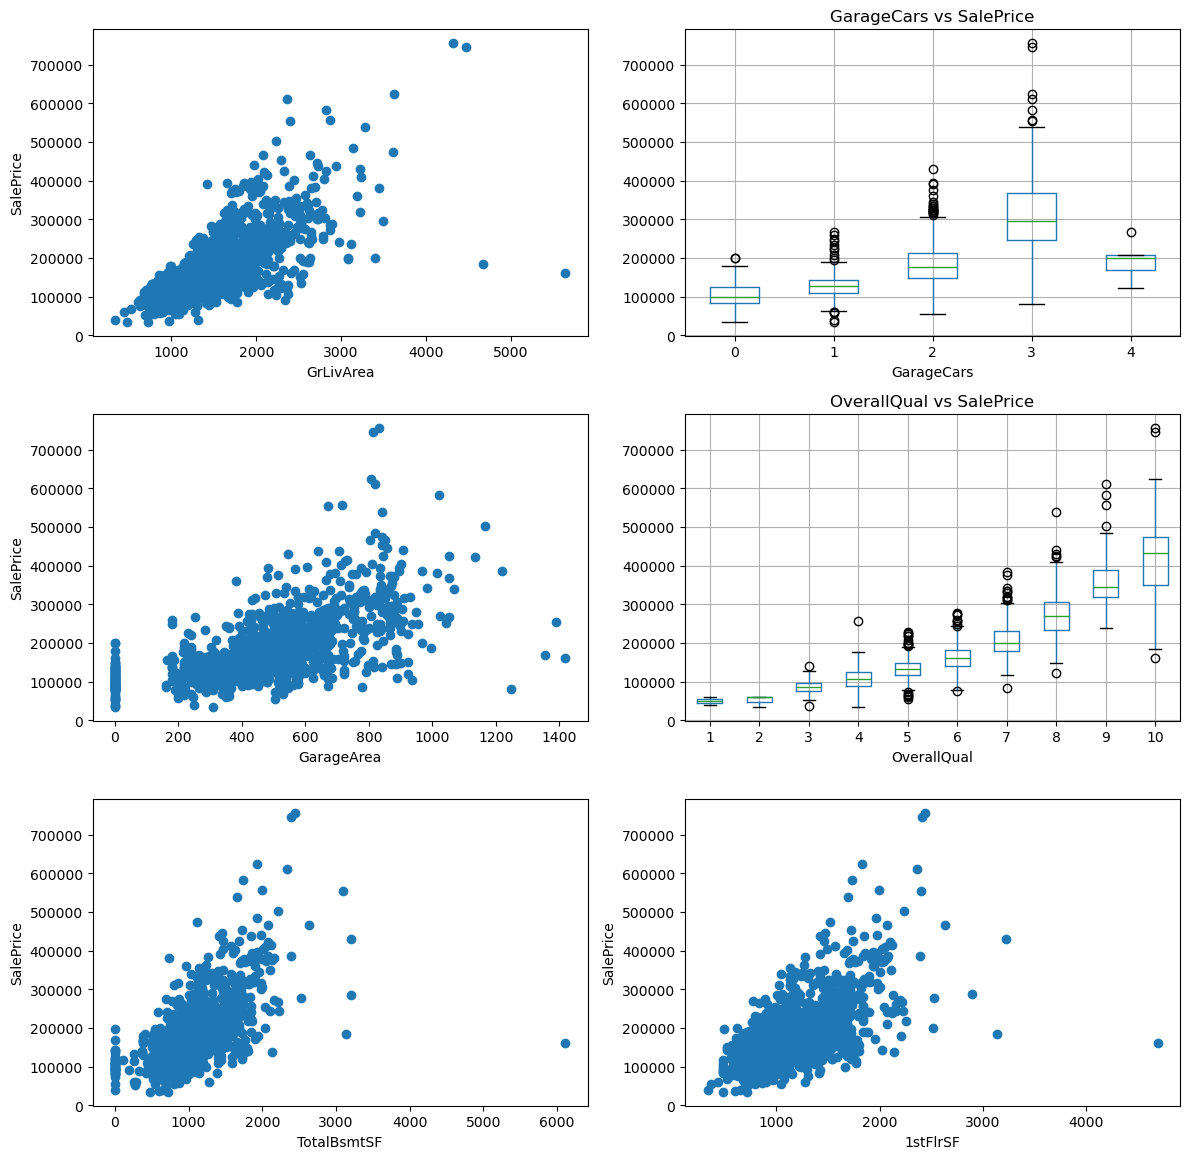

In [27]:
fig, ax = plt.subplots(3, 2, figsize=(12, 12))

# scatter plot for numeric features
ax[0, 0].scatter(house_pricing["GrLivArea"], house_pricing["SalePrice"])
ax[0, 0].set_xlabel("GrLivArea")
ax[0, 0].set_ylabel("SalePrice")

ax[1, 0].scatter(house_pricing["GarageArea"], house_pricing["SalePrice"])
ax[1, 0].set_xlabel("GarageArea")
ax[1, 0].set_ylabel("SalePrice")

ax[2, 0].scatter(house_pricing["TotalBsmtSF"], house_pricing["SalePrice"])
ax[2, 0].set_xlabel("TotalBsmtSF")
ax[2, 0].set_ylabel("SalePrice")

ax[2, 1].scatter(house_pricing["1stFlrSF"], house_pricing["SalePrice"])
ax[2, 1].set_xlabel("1stFlrSF")
ax[2, 1].set_ylabel("SalePrice")

# boxplot for categorical features
house_pricing.boxplot(
    column="SalePrice",
    by="GarageCars",
    ax=ax[0, 1]
)
ax[0, 1].set_title("GarageCars vs SalePrice")
ax[0, 1].set_xlabel("GarageCars")

house_pricing.boxplot(
    column="SalePrice",
    by="OverallQual",
    ax=ax[1, 1]
)
ax[1, 1].set_title("OverallQual vs SalePrice")
ax[1, 1].set_xlabel("OverallQual")

plt.tight_layout()
plt.suptitle("")
plt.show()

The scatter plots show two houses with more than 4,000 sq ft of living area that sold for under $200,000. These are the partial sales that the dataset's author (De Cock, 2011) recommends removing, so they are dropped here, from the **training data only**.

The other filters considered earlier (`GarageArea > 1200`, `TotalBsmtSF > 6000`, `1stFlrSF > 4000`, each with price under $200k) mostly catch the same house (Id 1299) plus two large-garage houses (Ids 1062, 1191) with no documented reason to be anomalies. Adding them made the baseline CV slightly worse (0.1199 vs 0.1187 for XGBoost), so only the living-area filter is applied.

**Caveat:** removing outliers also removes them from the validation folds, so part of the CV improvement comes from the folds getting easier. The test set still contains whatever houses it contains.

In [28]:
outlier_mask = (house_pricing['GrLivArea'] > 4000) & (house_pricing['SalePrice'] < 200000)
print("Removing Ids:", house_pricing.loc[outlier_mask, 'Id'].tolist())

house_pricing = house_pricing[~outlier_mask].reset_index(drop=True)
house_pricing.shape

Removing Ids: [524, 1299]


(1458, 81)

### 3.5 Feature engineering

In [29]:
ENGINEERED_FEATURES = ['FootprintSize', 'AvgRoomSize', 'GarageAge', 'HouseAge',
                       'GarageBuiltLater', 'AreaPerCar']


def add_engineered_features(df):
    """Same features for train and test."""
    df = df.copy()
    # FootprintSize = max(1stFlrSF, TotalBsmtSF)
    df["FootprintSize"] = np.maximum(df["1stFlrSF"], df["TotalBsmtSF"])
    # AvgRoomSize = GrLivArea / TotRmsAbvGrd
    df["AvgRoomSize"] = df["GrLivArea"] / df["TotRmsAbvGrd"]
    # GarageAge = YrSold - GarageYrBlt  (NaN when there is no garage)
    df["GarageAge"] = df["YrSold"] - df["GarageYrBlt"]
    # HouseAge = YrSold - YearBuilt
    df["HouseAge"] = df["YrSold"] - df["YearBuilt"]
    # GarageBuiltLater = GarageYrBlt > YearBuilt
    df["GarageBuiltLater"] = (df["GarageYrBlt"] > df["YearBuilt"]).astype(int)
    # AreaPerCar = GarageArea / (GarageCars + 1)
    df["AreaPerCar"] = df["GarageArea"] / (df["GarageCars"] + 1)
    return df


house_pricing = add_engineered_features(house_pricing)

The column lists in `FEATURE_TYPES` were built before these columns existed. `ColumnTransformer` silently **drops** any column not listed (`remainder='drop'`), so the engineered features have to be added to the numeric list explicitly, or XGBoost and LightGBM never see them.

In [30]:
numeric_features = numeric_features + [f for f in ENGINEERED_FEATURES if f not in numeric_features]
FEATURE_TYPES["numeric"] = numeric_features

print(len(FEATURE_TYPES["numeric"]), len(FEATURE_TYPES["ordinal"]), len(FEATURE_TYPES["nominal"]))

39 18 28


### 3.6 Normalizing the target

In [31]:
# log transforming the target
house_pricing["SalePrice"] = np.log1p(house_pricing["SalePrice"])

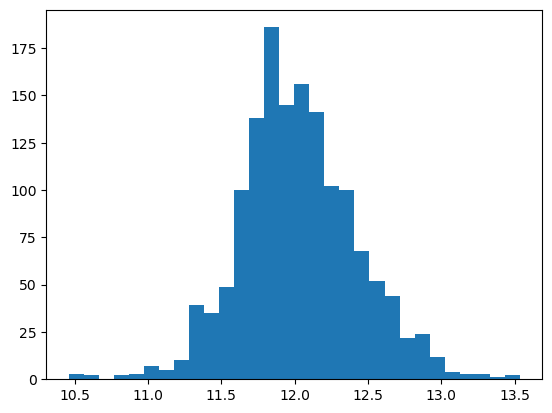

In [32]:
plt.hist(house_pricing["SalePrice"], bins=30);

## 4. Modelling Strategy

### 4.1 Problem Framing

- Task: Regression
- Target: `SalePrice` (log-transformed)
- Metric: RMSE
    - After log-transforming the target, RMSE(log y) = RMSLE(y)

### 4.2 Validation Strategy


 - 5-fold cross-validation, shuffled, random seed = 42
 - The **same folds** for every model, in baselines, tuning and the ensemble, so scores are comparable
 - Hyperparameter tuning with Optuna (TPE sampler, seeded for reproducibility)
 - All preprocessing that learns from data (imputers, encoders) sits inside a `Pipeline`, so it is refit on each training fold

### 4.3 Model Selection

- XGBoost: Strong baseline, handles non linearities
- LightGBM: Fast, Handles large feature space
- CatBoost: Handles categorical features natively

## 5. Baseline Models

In [33]:
import numpy as np
import pandas as pd

from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from xgboost import XGBRegressor

In [34]:
house_pricing.head(5)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,YrSold,SaleType,SaleCondition,SalePrice,FootprintSize,AvgRoomSize,GarageAge,HouseAge,GarageBuiltLater,AreaPerCar
0,1,60,RL,65.0,8450,Pave,None,Reg,Lvl,AllPub,...,2008,WD,Normal,12.247699,856,213.750000,5.0,5,0,182.666667
1,2,20,RL,80.0,9600,Pave,None,Reg,Lvl,AllPub,...,2007,WD,Normal,12.109016,1262,210.333333,31.0,31,0,153.333333
2,3,60,RL,68.0,11250,Pave,None,IR1,Lvl,AllPub,...,2008,WD,Normal,12.317171,920,297.666667,7.0,7,0,202.666667
3,4,70,RL,60.0,9550,Pave,None,IR1,Lvl,AllPub,...,2006,WD,Abnorml,11.849405,961,245.285714,8.0,91,1,160.500000
4,5,60,RL,84.0,14260,Pave,None,IR1,Lvl,AllPub,...,2008,WD,Normal,12.429220,1145,244.222222,8.0,8,0,209.000000


In [35]:
X = house_pricing.drop(columns=["SalePrice", "Id"])
y = house_pricing["SalePrice"]

In [36]:
# custom encoder
from sklearn.base import BaseEstimator, TransformerMixin


class OrdinalMapper(BaseEstimator, TransformerMixin):
    def __init__(self, mappings):
        self.mappings = mappings

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        for col, mapping in self.mappings.items():
            if mapping is not None:
                X[col] = X[col].fillna("None").map(mapping)
        return X

In [37]:
# preprocessing pipelines

# numeric pipeline
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
])

# categorical pipeline
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),  # first we imputr the missing values
    ("onehot", OneHotEncoder(handle_unknown="ignore")),  # then we on hot encode them
])

# ordinal pipeline
ordinal_pipeline = Pipeline([
    ("mapper", OrdinalMapper(ordinal_mappings))
])

# combining them
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, FEATURE_TYPES["numeric"]),
    ("cat", categorical_pipeline, FEATURE_TYPES["nominal"]),
    ("ord", ordinal_pipeline, FEATURE_TYPES["ordinal"])
])

### 5.1 XGBoost

In [38]:
# baseline XGBoost
xgb_model = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

In [39]:
# full pipeline
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", xgb_model)
])

In [40]:
# cross validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    pipeline,
    X,
    y,
    scoring="neg_root_mean_squared_error",
    cv=kf,
    n_jobs=-1
)

rmse_scores = -scores

In [41]:
# evaluation dictionary maker
def make_eval_dict(sc_arr):
    sc_dict = {
        "CV RMSE": sc_arr,
        "Mean RMSE": sc_arr.mean(),
        "Std RMSE": sc_arr.std()
    }

    return sc_dict

In [42]:
XGB_base_scores = make_eval_dict(rmse_scores)
print(XGB_base_scores)

{'CV RMSE': array([0.12238579, 0.10854281, 0.12526783, 0.12637598, 0.10646056]), 'Mean RMSE': np.float64(0.11780659423710385), 'Std RMSE': np.float64(0.008539597630076374)}


### 5.2 LightGBM

Note: LightGBM only applies `subsample` when `subsample_freq` > 0. Without it, bagging is silently off.

In [43]:
from lightgbm import LGBMRegressor

lgb_model = LGBMRegressor(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=-1,  # no limit (tree grows naturally)
    num_leaves=31,  # default, important param
    subsample=0.8,
    subsample_freq=1,  # without this, subsample is ignored
    verbose=-1,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

In [44]:
pipeline_lgb = Pipeline([
    ("preprocessor", preprocessor),
    ("model", lgb_model)
])

In [45]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    pipeline_lgb,
    X,
    y,
    scoring="neg_root_mean_squared_error",
    cv=kf,
    n_jobs=-1
)

rmse_scores = -scores

In [46]:
LGBM_base_scores = make_eval_dict(rmse_scores)
print(LGBM_base_scores)

{'CV RMSE': array([0.12481138, 0.11866319, 0.13450506, 0.12654846, 0.11010702]), 'Mean RMSE': np.float64(0.12292702238093908), 'Std RMSE': np.float64(0.008163934497869531)}


### 5.3 CatBoost

CatBoost gets the raw columns rather than the `ColumnTransformer` output, because it encodes categorical features itself (ordered target statistics).

- **Nominal** columns are passed as strings in `cat_features`.
- **Ordinal** columns are mapped to integers with the same `OrdinalMapper`, so their order (Po < Fa < TA < Gd < Ex) is kept. Passing them as unordered strings throws that order away.
- No `eval_set`: with an eval set, CatBoost keeps the iteration that scores best **on that set**, which would be the validation fold being scored. That makes the CV result optimistic.

In [47]:
from sklearn.metrics import mean_squared_error


def make_catboost_frame(df):
    """Ordinals -> integers, nominals -> strings (CatBoost's cat_features)."""
    df = OrdinalMapper(ordinal_mappings).transform(df)
    for col in FEATURE_TYPES["nominal"]:
        df[col] = df[col].astype(str)
    return df


X_cb = make_catboost_frame(house_pricing.drop(columns=["SalePrice", "Id"]))
y_cb = house_pricing["SalePrice"]

In [48]:
# categorical (nominal) column indices
cat_features_indices = [X_cb.columns.get_loc(col) for col in FEATURE_TYPES["nominal"]]
len(cat_features_indices)

28

In [49]:
# model
from catboost import CatBoostRegressor

cat_model = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.05,
    depth=6,
    loss_function='RMSE',
    random_seed=42,
    verbose=0
)

In [50]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

rmse_scores = []

for train_idx, val_idx in kf.split(X_cb):
    X_train, X_val = X_cb.iloc[train_idx], X_cb.iloc[val_idx]
    y_train, y_val = y_cb.iloc[train_idx], y_cb.iloc[val_idx]

    cat_model.fit(X_train, y_train, cat_features=cat_features_indices, verbose=0)

    preds = cat_model.predict(X_val)
    rmse_scores.append(np.sqrt(mean_squared_error(y_val, preds)))

In [51]:
rmse_scores = pd.Series(rmse_scores)
cb_base_scores = make_eval_dict(rmse_scores)
print(cb_base_scores)

{'CV RMSE': 0    0.117926
1    0.109264
2    0.120906
3    0.125224
4    0.100935
dtype: float64, 'Mean RMSE': np.float64(0.1148509624095864), 'Std RMSE': 0.00972874940961969}


### 5.4 Comparing the baseline models

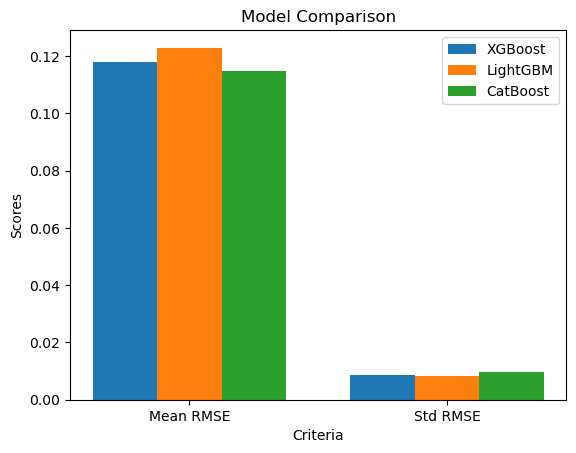

In [52]:
keys = list(XGB_base_scores.keys())[1:]

x = np.arange(len(keys))
width = 0.25

plt.bar(x - width, list(XGB_base_scores.values())[1:], width, label='XGBoost')
plt.bar(x, list(LGBM_base_scores.values())[1:], width, label='LightGBM')
plt.bar(x + width, list(cb_base_scores.values())[1:], width, label='CatBoost')

plt.xticks(x, keys)
plt.legend()
plt.title("Model Comparison")
plt.xlabel("Criteria")
plt.ylabel("Scores")

plt.show();

I'll go forward and fine tune XGBoost and CatBoost as LightGBM performed slightly worse and is more sensitive to hyperparameter tuning

## 6. Fine Tuning Selected Models (using Optuna)

### 6.1 XGBoost

In [53]:
# defining objective function

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 500, 2000),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 8),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 0, 5),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 10),
        "random_state": 42,
        "n_jobs": -1
    }

    model = XGBRegressor(**params)

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    scores = cross_val_score(
        pipeline,
        X,
        y,
        scoring="neg_root_mean_squared_error",
        cv=kf,
        n_jobs=-1
    )

    return -scores.mean()  # minimize RMSE

In [54]:
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)

study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=30)

In [55]:
print("Best RMSE:", study.best_value)
print("Best params:", study.best_params)

Best RMSE: 0.11669822850839943
Best params: {'n_estimators': 1713, 'learning_rate': 0.020165721691808594, 'max_depth': 3, 'subsample': 0.8736932106048627, 'colsample_bytree': 0.7760609974958406, 'reg_alpha': 0.6101911742238941, 'reg_lambda': 5.002251410101574}


In [56]:
optuna.visualization.plot_optimization_history(study)
optuna.visualization.plot_param_importances(study)

### 6.2 CatBoost

In [57]:
def objective_cat(trial):
    params = {
        "iterations": trial.suggest_int("iterations", 500, 1500),
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.1, log=True),
        "depth": trial.suggest_int("depth", 4, 7),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1, 10),
        "random_seed": 42,
        "verbose": 0
    }

    model = CatBoostRegressor(**params)

    rmse_scores = []

    # same 5 folds as every other model; no eval_set, so the scored fold never picks the iteration
    for train_idx, val_idx in kf.split(X_cb):
        X_train, X_val = X_cb.iloc[train_idx], X_cb.iloc[val_idx]
        y_train, y_val = y_cb.iloc[train_idx], y_cb.iloc[val_idx]

        model.fit(X_train, y_train, cat_features=cat_features_indices, verbose=0)

        preds = model.predict(X_val)
        rmse_scores.append(np.sqrt(mean_squared_error(y_val, preds)))

    return np.mean(rmse_scores)

In [58]:
study2 = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
study2.optimize(objective_cat, n_trials=30)

In [59]:
print("Best RMSE:", study2.best_value)
print("Best params:", study2.best_params)

Best RMSE: 0.11436093461685186
Best params: {'iterations': 1028, 'learning_rate': 0.058037676463743235, 'depth': 6, 'l2_leaf_reg': 2.2968214094943433}


In [60]:
optuna.visualization.plot_optimization_history(study2)
optuna.visualization.plot_param_importances(study2)

### 6.3 Results so far
All scores below use the same 5 folds of the cleaned training data.

In [61]:
results = pd.DataFrame({
    "Model": ["XGBoost", "LightGBM", "CatBoost", "XGBoost (tuned)", "CatBoost (tuned)"],
    "Stage": ["Baseline", "Baseline", "Baseline", "Optuna, 30 trials", "Optuna, 30 trials"],
    "Mean CV RMSE": [XGB_base_scores["Mean RMSE"], LGBM_base_scores["Mean RMSE"], cb_base_scores["Mean RMSE"],
                     study.best_value, study2.best_value],
})
results["Mean CV RMSE"] = results["Mean CV RMSE"].astype(float).round(4)
results

,Model,Stage,Mean CV RMSE
0,XGBoost,Baseline,0.1178
1,LightGBM,Baseline,0.1229
2,CatBoost,Baseline,0.1149
3,XGBoost (tuned),"Optuna, 30 trials",0.1167
4,CatBoost (tuned),"Optuna, 30 trials",0.1144


## 7. Final single model (tuned CatBoost) and Kaggle submission

In [62]:
# rebuilding the model with the best params
best_params = study2.best_params

catb_best = CatBoostRegressor(
    **best_params
)

In [63]:
# creating the best pipeline
pipeline_best = Pipeline([
    ("preprocessor", preprocessor),
    ("model", catb_best)
])

In [64]:
# training model on the entire data
pipeline_best.fit(X, y)

0:	learn: 0.3850718	total: 3.03ms	remaining: 3.11s
1:	learn: 0.3707509	total: 5.9ms	remaining: 3.03s
2:	learn: 0.3564283	total: 8.16ms	remaining: 2.79s
3:	learn: 0.3436073	total: 10.8ms	remaining: 2.76s
4:	learn: 0.3319353	total: 13.4ms	remaining: 2.73s
5:	learn: 0.3193560	total: 15.6ms	remaining: 2.66s
6:	learn: 0.3082616	total: 17.9ms	remaining: 2.62s
7:	learn: 0.2984699	total: 20.3ms	remaining: 2.58s
8:	learn: 0.2893287	total: 22.6ms	remaining: 2.56s
9:	learn: 0.2805291	total: 24.9ms	remaining: 2.54s
10:	learn: 0.2720817	total: 27.2ms	remaining: 2.52s
11:	learn: 0.2642153	total: 29.5ms	remaining: 2.5s
12:	learn: 0.2569134	total: 31.8ms	remaining: 2.48s
13:	learn: 0.2501228	total: 34.1ms	remaining: 2.47s
14:	learn: 0.2435208	total: 36.3ms	remaining: 2.45s
15:	learn: 0.2363276	total: 38.6ms	remaining: 2.44s
16:	learn: 0.2298540	total: 40.9ms	remaining: 2.43s
17:	learn: 0.2248312	total: 42.5ms	remaining: 2.38s
18:	learn: 0.2194046	total: 45ms	remaining: 2.39s
19:	learn: 0.2139740	total

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [65]:
# predicting on test data -- same structural fills and engineered features as training
test_data = pd.read_csv(os.path.join(DATA_DIR, 'test.csv'))
test_data = add_engineered_features(fill_structural_missing(test_data))
X_test = test_data.drop(columns=["Id"])

test_pred_log = pipeline_best.predict(X_test)
test_pred = np.expm1(test_pred_log)

D:\Important work\Artificial Intelligence\Projects\ml_env\lib\site-packages\sklearn\pipeline.py:61: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


In [66]:
# kaggle submission (single model)
submission = pd.DataFrame({
    "Id": test_data["Id"],
    "SalePrice": test_pred
})

submission.to_csv(os.path.join(OUTPUT_DIR, 'submission_xgb.csv'), index=False)

print("Single-model submission created: submission_xgb.csv")

Single-model submission created: submission_xgb.csv
